In [1]:
from dataframe_modify.add_positions import add_positions
from dataframe_modify.swap_perspective import swap_y
from dataframe_modify.swap_perspective import generalize_perspective
from dataframe_modify.grid_areas import add_grid_areas
from dataframe_modify.add_context import add_context
from get_data.get_data import get_merged_events
from get_data.get_data import get_sb360

MATCH_ID = 3836322

EVENTS_TO_ANALIZE = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'dribbles', 'blocks', 'clearances', 'duels',
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

frames = get_sb360(MATCH_ID)
events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)
start_team = events['possession_team'][0]

events = add_context(events, frames)
events = add_positions(events)
events = swap_y(events)
events = generalize_perspective(events, start_team)
events = add_grid_areas(events)

In [2]:
from sequences.get_sequences import get_sequences_by_possession

sequences = get_sequences_by_possession(events)
sequences[0]

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,context_locations,teammate_locations,actor_locations,start_x,start_y,end_x,end_y,start_area,end_area,area_code
0,91f5e387-8baa-47b0-82ba-b300bfc7a3bd,5,1,00:00:01.788,0,1,Pass,2,Lech Poznan,From Kick Off,...,[],[],[],61.0,39.9,44.0,40.6,G5,E4,G5E4
1,976e69a2-06f2-4693-8447-da5351af8239,6,1,00:00:02.937,0,2,Ball Receipt*,2,Lech Poznan,From Kick Off,...,"[[39.89566143614843, 26.75718526070478], [45.3...","[False, False, False, False, False, False, Tru...","[False, False, False, False, False, False, Fal...",44.0,40.6,,,E4,,E4
2,4aabd771-2bc6-4bfd-953a-1abe3b894626,7,1,00:00:02.937,0,2,Carry,2,Lech Poznan,From Kick Off,...,"[[80.10433856385157, 53.24281473929522], [74.6...","[False, False, False, False, False, False, Tru...","[False, False, False, False, False, False, Fal...",44.0,40.6,45.0,39.4,E4,E5,E4E5
3,5bb2c90b-c4e7-4ca4-b4f2-6d59d90651d3,8,1,00:00:03.698,0,3,Pass,2,Lech Poznan,From Kick Off,...,"[[82.42474475077002, 54.36488714005686], [76.4...","[False, False, False, False, False, True, True...","[False, False, False, False, False, False, Fal...",45.0,39.4,33.5,58.6,E5,D3,E5D3
4,60dcdfd7-becd-43d9-b577-a884dc83910c,9,1,00:00:05.181,0,5,Ball Receipt*,2,Lech Poznan,From Kick Off,...,"[[40.306550822439235, 17.551711562227773], [37...","[False, False, False, False, True, True, True,...","[False, False, False, False, False, False, Fal...",33.5,58.6,,,D3,,D3
5,13f58193-602d-4cb8-8e54-cfe6299117eb,10,1,00:00:05.181,0,5,Carry,2,Lech Poznan,From Kick Off,...,"[[79.69344917756077, 62.44828843777223], [82.4...","[False, False, False, False, True, True, True,...","[False, False, False, False, False, False, Fal...",33.5,58.6,33.5,58.6,D3,D3,D3D3
6,53751ba8-ff72-4bd2-bb90-99e55186fddc,11,1,00:00:06.327,0,6,Pass,2,Lech Poznan,From Kick Off,...,"[[78.21076348565485, 51.82178550530191], [74.4...","[False, False, True, False, False, True, False...","[False, False, False, False, False, False, Fal...",33.5,58.6,31.9,31.1,D3,D5,D3D5
7,ec5a8303-e619-43af-a9b3-b59361959f38,12,1,00:00:07.805,0,7,Ball Receipt*,2,Lech Poznan,From Kick Off,...,"[[42.75657034846516, 38.86986471215116], [45.5...","[False, False, False, False, True, True, False...","[False, False, False, False, False, False, Fal...",31.9,31.1,,,D5,,D5
8,3be60ad0-abce-446f-b42d-9c2cc3280c3d,13,1,00:00:07.805,0,7,Carry,2,Lech Poznan,From Kick Off,...,"[[77.24342965153484, 41.13013528784884], [74.4...","[False, False, False, False, True, True, False...","[False, False, False, False, False, False, Fal...",31.9,31.1,28.1,28.2,D5,C6,D5C6
9,499a6a9d-65a4-40b4-b5bb-50affebefceb,14,1,00:00:08.595,0,8,Pass,2,Lech Poznan,From Kick Off,...,"[[69.32088272399756, 45.685779881775325], [70....","[False, False, False, False, True, True, False...","[False, False, False, False, False, False, Fal...",28.1,28.2,28.8,9.5,C6,C8,C6C8


sequence 0
Team: Lech Poznan
1: Filip Bednarek (Pass) <00:28:29.571>
2: Mikael Ishak (Ball Receipt*) <00:28:33.067>
2: Mikael Ishak (Duel) <00:28:33.067>


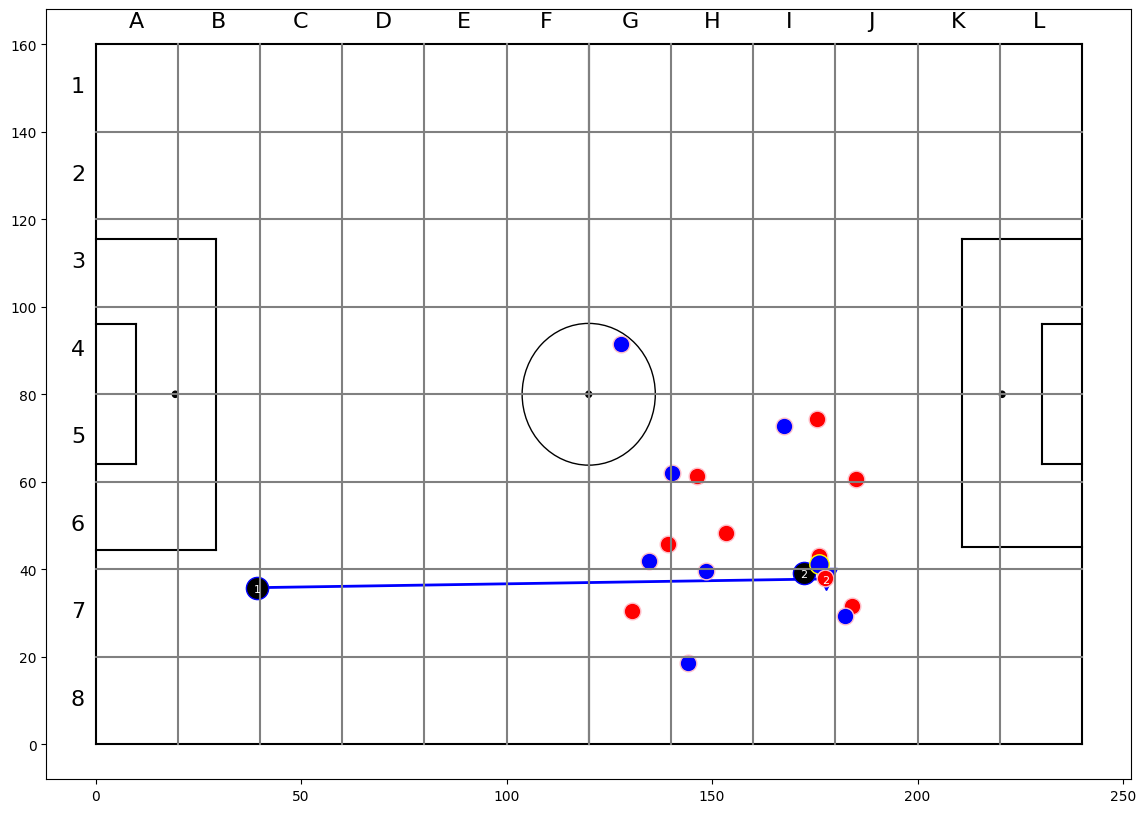

In [3]:
from draw.draw_sequences import draw_events_sequence
from sequences.find_fast_actions import find_fast_actions

fast_attact_lech_1 = find_fast_actions(sequences=sequences, team='Lech Poznan', start_team=start_team, half=1)

for i, s in enumerate(fast_attact_lech_1):
    print(f'sequence {i}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)

sequence 0
Team: Jagiellonia Białystok
1: Bogdan Ionuț Țîru (Pass) <00:22:37.859>
2: Tomáš Přikryl (Ball Receipt*) <00:22:39.557>
2: Tomáš Přikryl (Carry) <00:22:39.557>
2: Tomáš Přikryl (Pass) <00:22:40.685>
3: Bojan Nastić (Ball Receipt*) <00:22:41.418>
3: Bojan Nastić (Carry) <00:22:41.418>


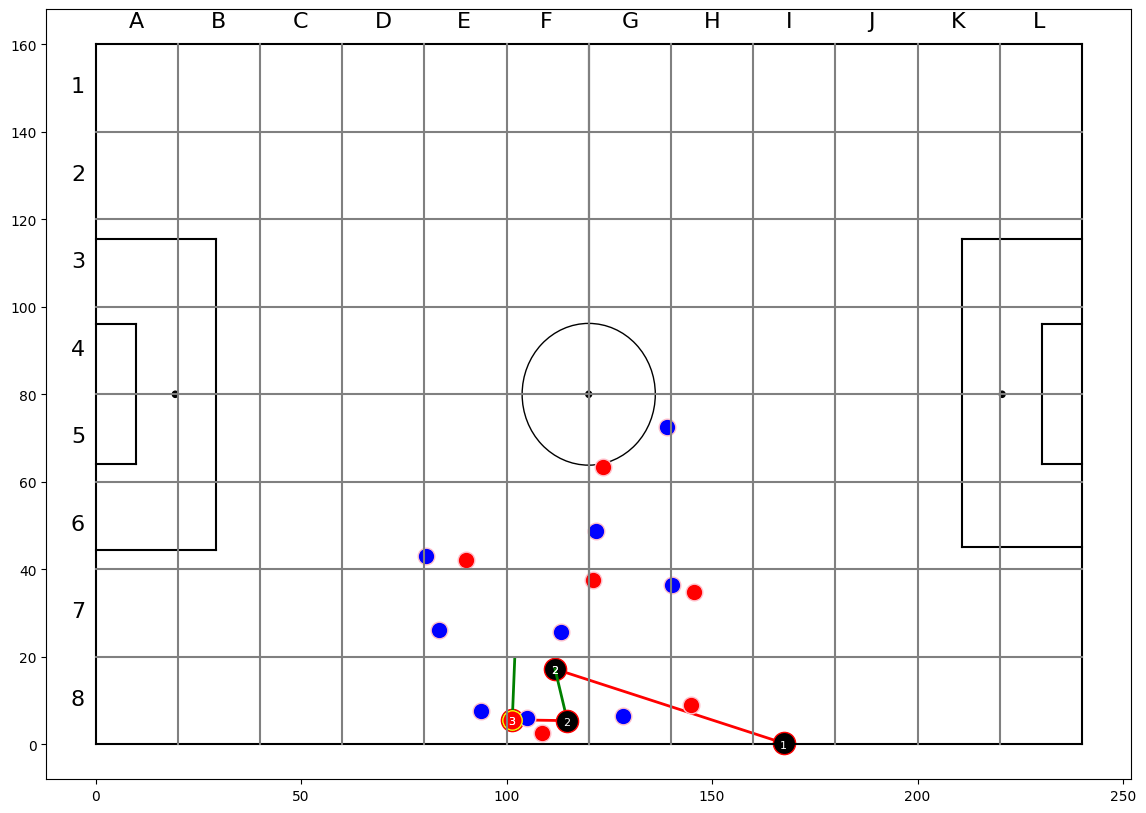

sequence 1
Team: Jagiellonia Białystok
1: Mateusz Skrzypczak (Pass) <00:25:20.744>
2: Israel Puerto Pineda (Ball Receipt*) <00:25:21.889>
2: Israel Puerto Pineda (Carry) <00:25:21.889>
2: Israel Puerto Pineda (Pass) <00:25:23.440>
3: Wojciech Łaski (Ball Receipt*) <00:25:24.437>


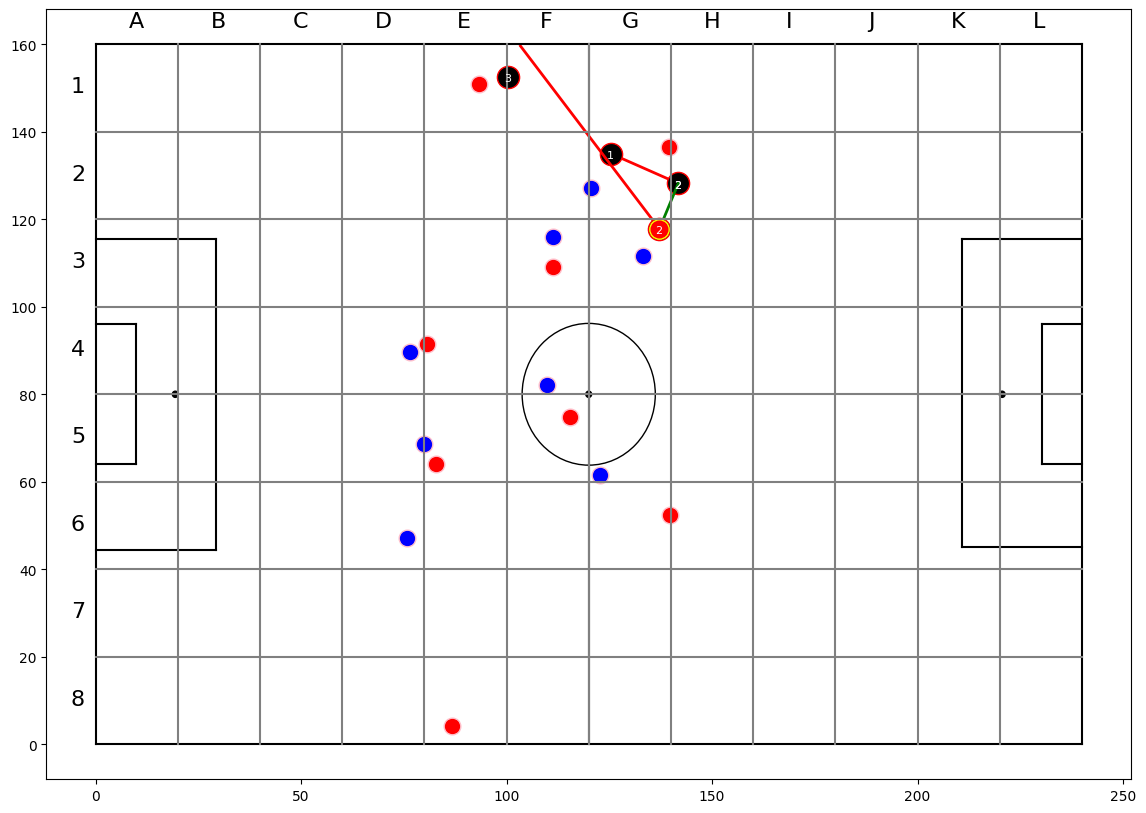

In [4]:
from draw.draw_sequences import draw_events_sequence
from sequences.find_fast_actions import find_fast_actions

fast_attact_jagiellonia_1 = find_fast_actions(sequences=sequences, team='Jagiellonia Białystok', start_team=start_team, half=1)

for i, s in enumerate(fast_attact_jagiellonia_1):
    print(f'sequence {i}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)

In [5]:
from draw.draw_sequences import draw_events_sequence
from sequences.find_fast_actions import find_fast_actions

fast_attact_lech_2 = find_fast_actions(sequences=sequences, team='Lech Poznan', start_team=start_team, half=2)

for i, s in enumerate(fast_attact_lech_2):
    print(f'sequence {i}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)

In [6]:
from draw.draw_sequences import draw_events_sequence
from sequences.find_fast_actions import find_fast_actions

fast_attact_jagiellonia_2 = find_fast_actions(sequences=sequences, team='Jagiellonia Białystok', start_team=start_team, half=2)

for i, s in enumerate(fast_attact_jagiellonia_2):
    print(f'sequence {i}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)